# Gen1 mesh convergence · 729 nm

Import the `Gen1_FINAL/729_nm` height scan using the same loading, Gaussian-cut fitting, and focus models as `Mesh_convergence_study.ipynb`. Functions live in `focus_scan_analysis.py`; paths and analysis choices are configured below.

The current folder provides **one scan**. Add further mesh cases to `DATASETS` for comparisons. Beam waists are **1/e² intensity radii**, not diameters. Raw peak intensity is compared across planes; only the map and its cuts are normalized.

Lumerical exports `P[x, y]`; the loader converts this to an image indexed `[y, x]` and mirrors x together with the data, following the existing laboratory convention. File heights are absolute z coordinates. Heights above the chip use **z − 6 µm**, inherited from the previous study and configurable below.


In [10]:
from pathlib import Path
import sys

analysis_dir = Path.cwd() if (Path.cwd() / "focus_scan_analysis.py").is_file() else Path.cwd() / "Analysis"
if str(analysis_dir) not in sys.path:
    sys.path.insert(0, str(analysis_dir))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import importlib
import focus_scan_analysis
importlib.reload(focus_scan_analysis)
from focus_scan_analysis import (
    set_figure_style, load_focus_scan, fit_focus_scan, report_focus_scan,
    plot_focus_plane, plot_focus_observables, plot_focus_propagation,
    plot_focus_comparison, plot_focus_mesh_convergence,
)
set_figure_style("Arial", 12)


In [11]:
DATASETS = {
    "Gen1 · 729 nm": Path(
        "/home/philip_jacobson/Desktop/Yiyang_Zhi/data/results/"
        "Integrated_Trapped_Ions_Library/Gen1_FINAL/729_nm"
    ),
}
CHIP_SURFACE_HEIGHT_UM = 5.0
POWER_ARRAY_AXES = "xy"
MIRROR_X = True
FOCUS_AXIS = "y"
INTENSITY_EXPONENT = 0.5  # Same one-axis Gaussian propagation model as the previous study.
SELECTED_HEIGHT_UM = None  # Absolute z in µm; None selects maximum sampled intensity.
MESH_DIVIDERS = {}  # Fill by dataset label when mesh-divider metadata is available.

FIGURE_DIR = analysis_dir / "figures/mesh_convergence_gen1"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
focus_results = {}
focus_figures = {}


In [12]:
for label, directory in DATASETS.items():
    scan = fit_focus_scan(
        load_focus_scan(directory, chip_surface_um=CHIP_SURFACE_HEIGHT_UM,
                        mirror_x=MIRROR_X, power_axes=POWER_ARRAY_AXES),
        focus_axis=FOCUS_AXIS, intensity_exponent=INTENSITY_EXPONENT,
    )
    focus_results[label] = scan
    report_focus_scan(scan, label)


Gen1 · 729 nm: 31 planes; absolute z 76–106 µm
  Chip surface z = 5 µm; focus radius axis = y
  Sampled intensity maximum: 72.000 µm above chip
  Intensity-model focus:     78.364 µm; R² = 0.768728
  Radius-model focus:        79.766 µm; R² = 0.782965
  Minimum fitted w_y:       0.4388 µm (1/e² radius)
  x profile: 28/31 planes do not resolve both 1/e² edges; widths rely on extrapolation.


## Intensity map and Gaussian beam cuts

Select a plane with `SELECTED_HEIGHT_UM`, or use the maximum sampled intensity. The x/y cuts pass through the measured peak in that plane. A window-limited profile does not contain both 1/e² edges, so its fitted radius relies on extrapolation.


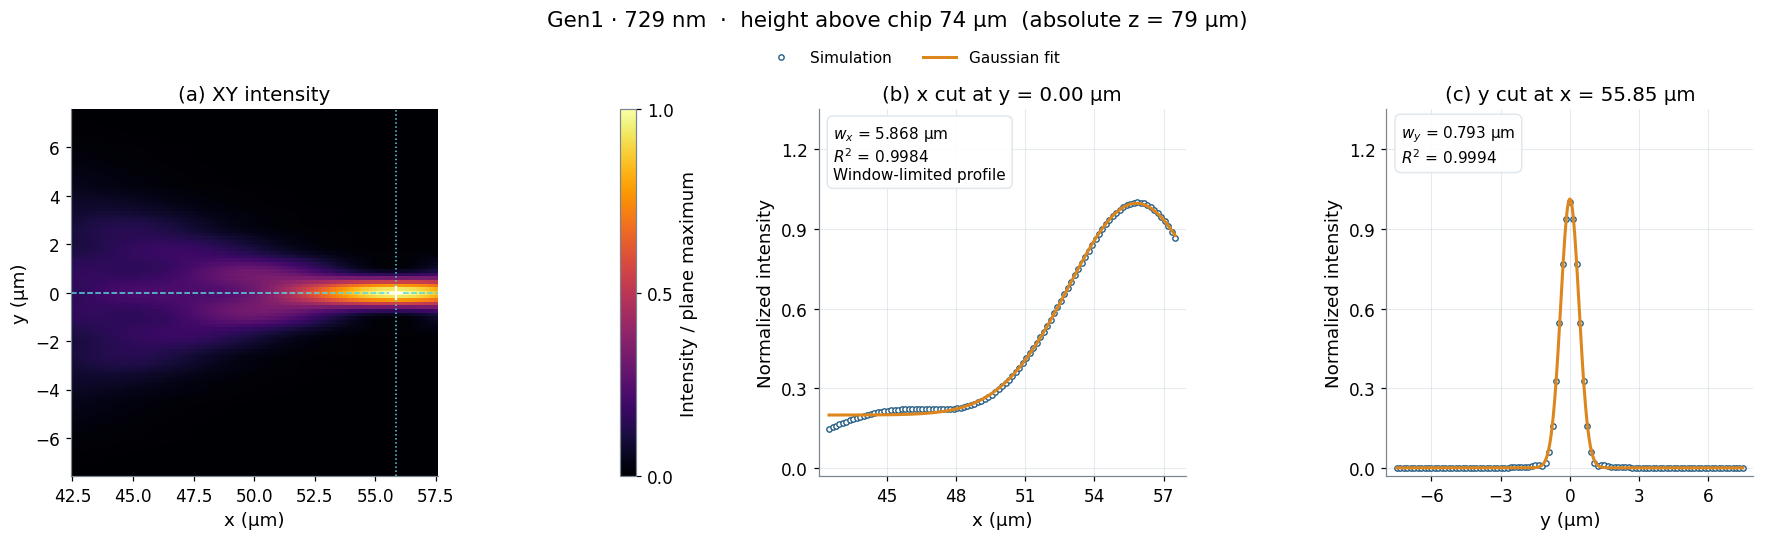

In [22]:
for label, scan in focus_results.items():
    fig, plane = plot_focus_plane(scan, label, height_um=79)
    focus_figures[(label, "plane")] = fig
    plt.show()


## Peak intensity and transverse beam waists

These are the sampled peak intensities and the Gaussian x/y radii at each height. Hollow markers identify window-limited radius estimates.


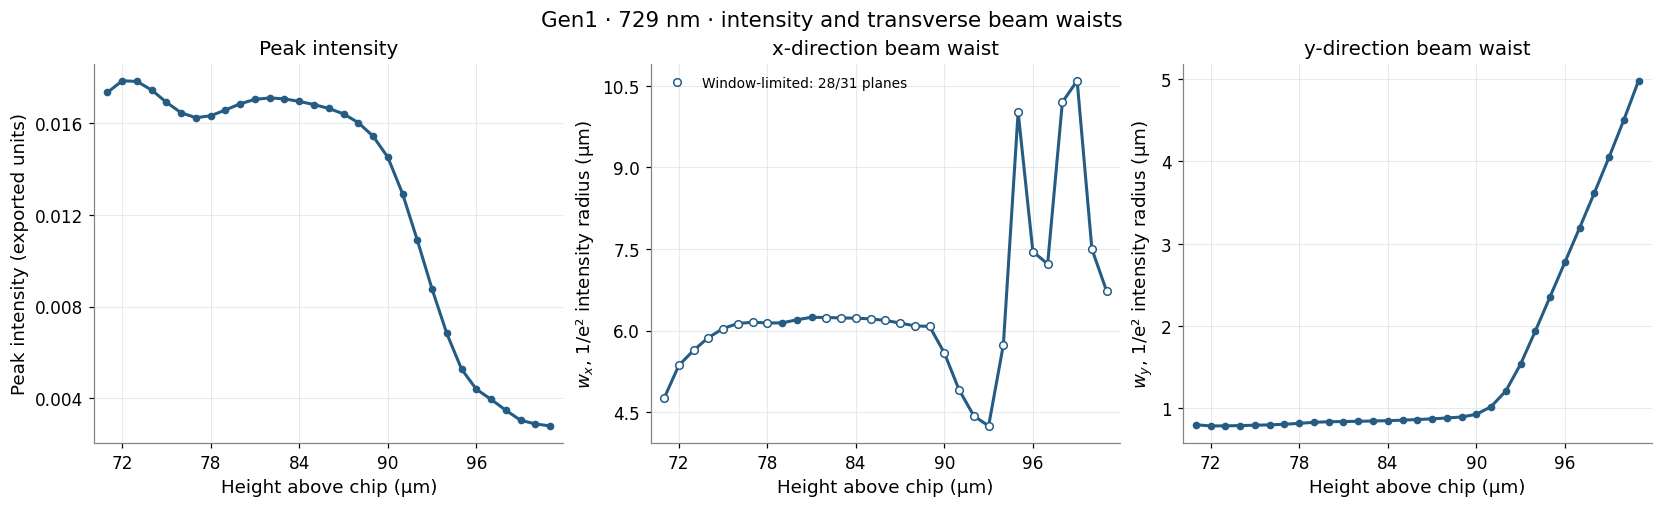

In [14]:
for label, scan in focus_results.items():
    fig = plot_focus_observables(scan, label)
    focus_figures[(label, "observables")] = fig
    plt.show()


## Intensity and y-radius focus fits

Peak intensity and y radius are fitted independently with the same propagation models as the previous study. Their focus heights need not agree. Inspect the measured curves and R² before using a fitted focus: a clipped lateral window can alter the measured peak and Gaussian propagation may not describe the whole scan.


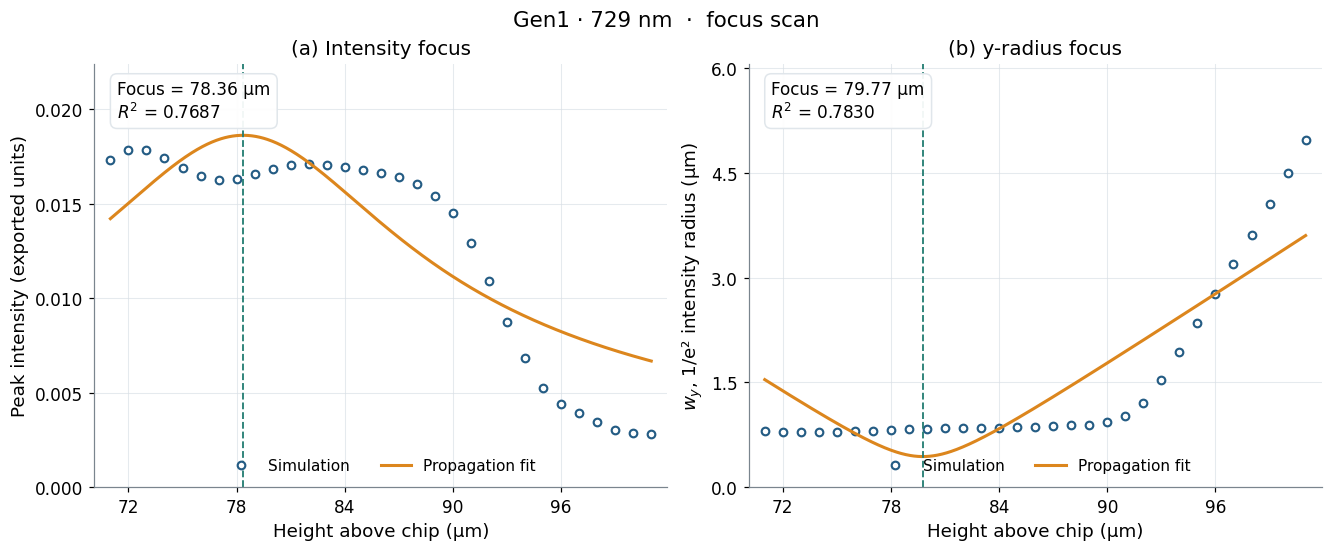

In [15]:
for label, scan in focus_results.items():
    fig = plot_focus_propagation(scan, label)
    focus_figures[(label, "focus")] = fig
    plt.show()


In [16]:
summary_lines = [
    "| Dataset | Sampled peak height (µm) | Intensity-fit focus (µm) | Intensity R² | Radius-fit focus (µm) | Radius R² | Minimum fitted radius (µm) |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for label, scan in focus_results.items():
    fit = scan["focus_fit"]
    summary_lines.append(
        f"| {label} | {fit['sampled_peak_above_chip_um']:.3f} | "
        f"{fit['intensity_focus_above_chip_um']:.3f} | {fit['intensity_r_squared']:.4f} | "
        f"{fit['waist_focus_above_chip_um']:.3f} | {fit['waist_r_squared']:.4f} | "
        f"{fit['minimum_radius_um']:.4f} |"
    )
display(Markdown("Heights are **above the chip surface**; the fitted radius uses the "
                 + FOCUS_AXIS + " direction." + chr(10)*2 + chr(10).join(summary_lines)))


Heights are **above the chip surface**; the fitted radius uses the y direction.

| Dataset | Sampled peak height (µm) | Intensity-fit focus (µm) | Intensity R² | Radius-fit focus (µm) | Radius R² | Minimum fitted radius (µm) |
|---|---:|---:|---:|---:|---:|---:|
| Gen1 · 729 nm | 72.000 | 78.364 | 0.7687 | 79.766 | 0.7830 | 0.4388 |

In [17]:
# These comparisons become available when more mesh cases are added above.
if len(focus_results) > 1:
    fig = plot_focus_comparison(focus_results)
    fig.suptitle("Gen1 · Focus Analysis across Mesh Settings")
    focus_figures[("comparison", "scans")] = fig
    plt.show()
    if all(label in MESH_DIVIDERS for label in focus_results):
        ordered_labels = sorted(focus_results, key=MESH_DIVIDERS.get)
        ordered_scans = {label: focus_results[label] for label in ordered_labels}
        fig = plot_focus_mesh_convergence([MESH_DIVIDERS[label] for label in ordered_labels], ordered_scans)
        focus_figures[("comparison", "convergence")] = fig
        plt.show()


In [18]:
# Save figures as PNG and PDF; exports stay alongside the analysis, not the raw data.
for (label, kind), fig in focus_figures.items():
    case_number = list(DATASETS).index(label) + 1 if label in DATASETS else "all"
    stem = f"gen1_{case_number}_{kind}"
    fig.savefig(FIGURE_DIR / (stem + ".png"), dpi=160, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / (stem + ".pdf"), bbox_inches="tight")
print(f"Saved {len(focus_figures)} figures (PNG/PDF) to {FIGURE_DIR}")


Saved 3 figures (PNG/PDF) to /home/philip_jacobson/GIT/integrated_trapped_ions/Analysis/figures/mesh_convergence_gen1
